# EM43 Evaluator — y = a * b

This notebook evaluates the two-input `multiply_ab` task. It loads the two saved genomes, runs representative held-out pairs, draws a space-time diagram, and reports probe/full-grid results.

**Important:** the Trainer in this bundle uses the existing two-input template from your uploaded notebook (`a,b=0..8`, `Le=100`) and changes its target to multiplication. The paper reports 2 runs, 800 generations and `Lp=50`, but Table 1 does not state the complete pair-generation protocol. The held-out probe set below is therefore an explicit evaluation protocol for this notebook, not a claim that it is identical to the paper's private test split.

Run this after `trainer_multiply_ab.ipynb` has saved both genomes.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import ast
import numpy as np
import matplotlib.pyplot as plt

DRIVE_ROOT = Path("/content/drive/MyDrive/EM43")
print("DRIVE_ROOT =", DRIVE_ROOT.resolve())
import pandas as pd


Mounted at /content/drive
DRIVE_ROOT = /content/drive/MyDrive/EM43


In [2]:
def lut_idx4(l: int, c: int, r: int) -> int:
    return (l * 4 + c) * 4 + r


IDX_000 = lut_idx4(0, 0, 0)
IDX_020 = lut_idx4(0, 2, 0)
IDX_200 = lut_idx4(2, 0, 0)
IDX_002 = lut_idx4(0, 0, 2)


def enforce_immutables_full(rule_full: np.ndarray) -> None:
    if rule_full.shape[-1] != 64:
        raise ValueError(f"rule_full last dimension must be 64, got {rule_full.shape}")
    rule_full[..., IDX_000] = 0
    rule_full[..., IDX_020] = 2
    rule_full[..., IDX_200] = 0
    rule_full[..., IDX_002] = 0


def parse_uint8_vector_string(s: str, expected_len: int | None = None, name: str = "vector") -> np.ndarray:
    s = s.strip()
    if not s:
        raise ValueError(f"{name} string is empty")

    if s[0] != "[":
        s = "[" + s + "]"

    try:
        obj = ast.literal_eval(s)
    except Exception as e:
        raise ValueError(f"Could not parse {name} string: {e}") from e

    arr = np.asarray(obj, dtype=np.int64).reshape(-1)

    if expected_len is not None and arr.shape[0] != expected_len:
        raise ValueError(f"{name} must have length {expected_len}, got {arr.shape[0]}")
    if np.any(arr < 0) or np.any(arr > 3):
        raise ValueError(f"{name} values must be in {{0,1,2,3}}")

    return arr.astype(np.uint8)


def parse_rule_program_strings(rule_str: str, prog_str: str):
    rule = parse_uint8_vector_string(rule_str, expected_len=64, name="rule")
    prog = parse_uint8_vector_string(prog_str, expected_len=None, name="program")
    enforce_immutables_full(rule)
    return rule, prog


def load_genome_from_drive(task_alias: str, run_id: int, drive_root: Path = DRIVE_ROOT):
    task_dir = drive_root / task_alias
    genome_path = task_dir / f"best_em43_{task_alias}_run_{run_id:03d}.npz"

    if not genome_path.exists():
        raise FileNotFoundError(f"Genome file not found: {genome_path}")

    data = np.load(genome_path, allow_pickle=True)

    rule_full = np.asarray(data["rule_full"], dtype=np.uint8).reshape(-1)
    program = np.asarray(data["program"], dtype=np.uint8).reshape(-1)

    if rule_full.shape != (64,):
        raise ValueError(f"Loaded rule has wrong shape: {rule_full.shape}")

    enforce_immutables_full(rule_full)

    meta = {
        "path": genome_path,
        "task_alias": str(data["task_alias"]) if "task_alias" in data else task_alias,
        "run": int(data["run"]) if "run" in data else run_id,
        "Lp": int(data["Lp"]) if "Lp" in data else int(program.shape[0]),
        "best_gen": int(data["best_gen"]) if "best_gen" in data else None,
        "fitness": float(data["fitness"]) if "fitness" in data else None,
        "mae": float(data["mae"]) if "mae" in data else None,
    }
    return rule_full, program, meta


def build_single_input_task(*, inputs, target_fn):
    xs = list(inputs)
    encoded_inputs = []
    targets = np.empty((len(xs),), dtype=np.int64)

    for i, x in enumerate(xs):
        if x < 0:
            raise ValueError(f"Input x={x} must be nonnegative")

        enc = np.zeros((x + 1,), dtype=np.uint8)
        enc[x] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(x))

    return encoded_inputs, targets


def build_two_input_task(*, pairs, target_fn):
    pairs = list(pairs)
    encoded_inputs = []
    targets = np.empty((len(pairs),), dtype=np.int64)

    for i, (a, b) in enumerate(pairs):
        if a < 0 or b < 0:
            raise ValueError(f"Inputs must be nonnegative, got {(a, b)}")

        L = max(a, b) + 1
        enc = np.zeros((L,), dtype=np.uint8)
        enc[a] = 2
        enc[b] = 2
        encoded_inputs.append(enc)
        targets[i] = int(target_fn(a, b))

    return encoded_inputs, targets


class EM43NumpyEvaluator:
    """
    Pure-numpy EM43 evaluator.

    Matches training semantics:
      - same tape layout: [program][separator][encoding]
      - same LUT indexing
      - same synchronous radius-1 update
      - same halting rule: live > 0 and 2*ctrl >= live
      - same time-0 halting check
      - same immutables
      - if live == 0, continue until T_max

    Inference difference:
      - no right-boundary invalidation
      - initial usable tape length is:
            Lp + Ls + (max active input position + 1) + right_padding
      - right-only self-extension before step
      - decode over the whole usable right region from the fixed encoding origin
      - no left extension
    """

    def __init__(
        self,
        *,
        Lp: int,
        Ls: int = 4,
        T_max: int = 10000,
        right_padding: int = 20,
        extend_margin: int = 3,
        extend_by: int = 20,
    ):
        self.Lp = int(Lp)
        self.Ls = int(Ls)
        self.T_max = int(T_max)
        self.right_padding = int(right_padding)
        self.extend_margin = int(extend_margin)
        self.extend_by = int(extend_by)

        if self.Lp <= 0:
            raise ValueError("Lp must be positive")
        if self.Ls < 0:
            raise ValueError("Ls must be nonnegative")
        if self.T_max <= 0:
            raise ValueError("T_max must be positive")
        if self.right_padding < 0:
            raise ValueError("right_padding must be nonnegative")
        if self.extend_margin < 0:
            raise ValueError("extend_margin must be nonnegative")
        if self.extend_by <= 0:
            raise ValueError("extend_by must be positive")

        self.enc_origin = self.Lp + self.Ls

    def _validate_inputs(self, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray):
        if rule_full.shape != (64,):
            raise ValueError(f"rule_full shape must be (64,), got {rule_full.shape}")
        if program.ndim != 1 or program.shape[0] != self.Lp:
            raise ValueError(f"program shape must be ({self.Lp},), got {program.shape}")
        if enc.ndim != 1:
            raise ValueError(f"encoding must be 1D, got shape {enc.shape}")
        if enc.shape[0] <= 0:
            raise ValueError("encoding must be non-empty")

        if np.any(rule_full < 0) or np.any(rule_full > 3):
            raise ValueError("rule values must be in {0,1,2,3}")
        if np.any(program < 0) or np.any(program > 3):
            raise ValueError("program values must be in {0,1,2,3}")
        if np.any(enc < 0) or np.any(enc > 3):
            raise ValueError("encoding values must be in {0,1,2,3}")

    def _build_initial_tape(self, program: np.ndarray, enc: np.ndarray) -> np.ndarray:
        active = np.flatnonzero(enc != 0)
        if active.size == 0:
            enc_len_used = enc.shape[0]
        else:
            enc_len_used = int(active[-1]) + 1

        usable_len = self.Lp + self.Ls + enc_len_used + self.right_padding

        tape = np.zeros((usable_len,), dtype=np.uint8)
        tape[:self.Lp] = program
        tape[self.enc_origin:self.enc_origin + enc.shape[0]] = enc
        return tape

    @staticmethod
    def _count_live_ctrl(tape: np.ndarray):
        live = int(np.count_nonzero(tape))
        ctrl = int(np.count_nonzero(tape == 3))
        return live, ctrl

    @staticmethod
    def _rightmost_active_index(tape: np.ndarray):
        pos = np.flatnonzero(tape != 0)
        return None if pos.size == 0 else int(pos[-1])

    def _extend_if_needed(self, tape: np.ndarray) -> np.ndarray:
        r_active = self._rightmost_active_index(tape)
        if r_active is None:
            return tape

        right_edge = tape.shape[0] - 1
        if right_edge - r_active <= self.extend_margin:
            tape = np.concatenate([tape, np.zeros((self.extend_by,), dtype=np.uint8)])
        return tape

    @staticmethod
    def _step_once(rule_full: np.ndarray, tape: np.ndarray) -> np.ndarray:
        L = np.empty_like(tape)
        C = tape
        R = np.empty_like(tape)

        L[0] = 0
        L[1:] = tape[:-1]

        R[-1] = 0
        R[:-1] = tape[1:]

        idx = (L.astype(np.int32) * 4 + C.astype(np.int32)) * 4 + R.astype(np.int32)
        return rule_full[idx].astype(np.uint8, copy=False)

    def _decode(self, tape: np.ndarray):
        decode_region = tape[self.enc_origin:]
        pos = np.flatnonzero(decode_region == 2)
        return None if pos.size == 0 else int(pos[-1])

    def run_single(self, *, rule_full: np.ndarray, program: np.ndarray, enc: np.ndarray, return_trajectory: bool = False):
        rule = np.asarray(rule_full, dtype=np.uint8).copy()
        prog = np.asarray(program, dtype=np.uint8).copy()
        enc = np.asarray(enc, dtype=np.uint8).copy()

        enforce_immutables_full(rule)
        self._validate_inputs(rule, prog, enc)

        tape = self._build_initial_tape(prog, enc)
        n_extensions = 0
        trajectory = [tape.copy()] if return_trajectory else None

        live, ctrl = self._count_live_ctrl(tape)
        if live > 0 and ctrl * 2 >= live:
            pred = self._decode(tape)
            return {
                "pred": pred,
                "valid": pred is not None,
                "halted": True,
                "halt_time": 0,
                "n_extensions": n_extensions,
                "final_usable_len": int(tape.shape[0]),
                "trajectory": trajectory,
            }

        for t in range(1, self.T_max + 1):
            old_len = tape.shape[0]
            tape = self._extend_if_needed(tape)
            if tape.shape[0] != old_len:
                n_extensions += 1

            tape = self._step_once(rule, tape)

            if return_trajectory:
                trajectory.append(tape.copy())

            live, ctrl = self._count_live_ctrl(tape)
            if live > 0 and ctrl * 2 >= live:
                pred = self._decode(tape)
                return {
                    "pred": pred,
                    "valid": pred is not None,
                    "halted": True,
                    "halt_time": t,
                    "n_extensions": n_extensions,
                    "final_usable_len": int(tape.shape[0]),
                    "trajectory": trajectory,
                }

        return {
            "pred": None,
            "valid": False,
            "halted": False,
            "halt_time": None,
            "n_extensions": n_extensions,
            "final_usable_len": int(tape.shape[0]),
            "trajectory": trajectory,
        }

    def plot_trajectory(self, trajectory, *, title="EM43 trajectory", figsize=(14, 6), tick_step=10):
        if trajectory is None or len(trajectory) == 0:
            raise ValueError("trajectory is empty")

        max_len = max(row.shape[0] for row in trajectory)
        img = np.zeros((len(trajectory), max_len), dtype=np.uint8)
        for i, row in enumerate(trajectory):
            img[i, :row.shape[0]] = row

        from matplotlib.colors import ListedColormap, BoundaryNorm

        cmap = ListedColormap(["white", "black", "red", "blue"])
        norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

        fig, ax = plt.subplots(figsize=figsize)
        ax.imshow(
            img,
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
            aspect="equal",   # square cells
            origin="upper",
        )

        # Left boundary before cell 0
        ax.axvline(x=-0.5, color="gray", linewidth=2)

        # Encoding origin boundary x0 = enc_origin
        ax.axvline(x=self.enc_origin - 0.5, color="green", linewidth=2)

        ax.set_xlabel("Encoding position (relative to x0)")
        ax.set_ylabel("Time step")
        ax.set_title(title)

        ax.set_xlim(-0.5, max_len - 0.5)
        ax.set_ylim(len(trajectory) - 0.5, -0.5)

        # X ticks labeled relative to encoding origin
        tick_start = self.enc_origin
        ticks = np.arange(tick_start, max_len, tick_step)
        ax.set_xticks(ticks)
        ax.set_xticklabels((ticks - self.enc_origin).astype(int))

        plt.show()

# 1. Load trained multiplication genomes

In [3]:
# =========================
# LOAD MULTIPLICATION GENOMES
# =========================
task_alias = "multiply_ab"
expected_runs = 2
task_dir = DRIVE_ROOT / task_alias
genome_paths = sorted(task_dir.glob(f"best_em43_{task_alias}_run_*.npz"))
print("Task directory:", task_dir)
print("Found genomes:", len(genome_paths))
for p in genome_paths:
    print(" -", p.name)
if len(genome_paths) != expected_runs:
    raise FileNotFoundError(
        f"Expected {expected_runs} genomes in {task_dir}, found {len(genome_paths)}. "
        "Run trainer_multiply_ab.ipynb first."
    )

run_id = 1
rule_full, program, meta = load_genome_from_drive(task_alias, run_id)
print("Loaded:", meta)
evaluator = EM43NumpyEvaluator(
    Lp=len(program), Ls=4, T_max=10000,
    right_padding=20, extend_margin=3, extend_by=20,
)
target_fn = lambda a, b: a * b


Task directory: /content/drive/MyDrive/EM43/multiply_ab
Found genomes: 2
 - best_em43_multiply_ab_run_001.npz
 - best_em43_multiply_ab_run_002.npz
Loaded: {'path': PosixPath('/content/drive/MyDrive/EM43/multiply_ab/best_em43_multiply_ab_run_001.npz'), 'task_alias': 'multiply_ab', 'run': 1, 'Lp': 50, 'best_gen': 674, 'fitness': -2.9152801036834717, 'mae': 2.9135801792144775}


# 2. Quick held-out probes

In [4]:
# Small held-out probe set: both inputs include values outside 0..8 training range
probe_pairs = [
    (9, 9),
    (9, 12),
    (10, 15),
    (14, 20),
    (20, 25),
    (25, 30),
    (30, 30),
]
probe_enc, probe_targets = build_two_input_task(
    pairs=probe_pairs, target_fn=target_fn
)
probe_rows = []
for (a, b), enc, expected in zip(probe_pairs, probe_enc, probe_targets):
    out = evaluator.run_single(
        rule_full=rule_full, program=program, enc=enc,
        return_trajectory=False,
    )
    pred = out["pred"]
    correct = bool(out["valid"] and pred is not None and int(pred) == int(expected))
    row = {
        "a": a, "b": b, "expected": int(expected), "predicted": pred,
        "valid": bool(out["valid"]), "correct": correct,
        "halt_time": out["halt_time"], "n_extensions": out["n_extensions"],
    }
    probe_rows.append(row)
    print(row)
probe_df = pd.DataFrame(probe_rows)
display(probe_df)
probe_df.to_csv(DRIVE_ROOT / "multiply_ab_representative_probes.csv", index=False)
print("Probe accuracy (not the paper's test metric):", probe_df["correct"].mean())


{'a': 9, 'b': 9, 'expected': 81, 'predicted': 62, 'valid': True, 'correct': False, 'halt_time': 69, 'n_extensions': 2}
{'a': 9, 'b': 12, 'expected': 108, 'predicted': 62, 'valid': True, 'correct': False, 'halt_time': 69, 'n_extensions': 2}
{'a': 10, 'b': 15, 'expected': 150, 'predicted': 60, 'valid': True, 'correct': False, 'halt_time': 67, 'n_extensions': 2}
{'a': 14, 'b': 20, 'expected': 280, 'predicted': 78, 'valid': True, 'correct': False, 'halt_time': 85, 'n_extensions': 3}
{'a': 20, 'b': 25, 'expected': 500, 'predicted': 110, 'valid': True, 'correct': False, 'halt_time': 117, 'n_extensions': 4}
{'a': 25, 'b': 30, 'expected': 750, 'predicted': 142, 'valid': True, 'correct': False, 'halt_time': 149, 'n_extensions': 5}
{'a': 30, 'b': 30, 'expected': 900, 'predicted': 160, 'valid': True, 'correct': False, 'halt_time': 167, 'n_extensions': 6}


,a,b,expected,predicted,valid,correct,halt_time,n_extensions
0,9,9,81,62,True,False,69,2
1,9,12,108,62,True,False,69,2
2,10,15,150,60,True,False,67,2
3,14,20,280,78,True,False,85,3
4,20,25,500,110,True,False,117,4
5,25,30,750,142,True,False,149,5
6,30,30,900,160,True,False,167,6


Probe accuracy (not the paper's test metric): 0.0


# 3. Space-time visualization

Input pair: (10, 15)
Prediction: 60
Expected: 150
Valid: True
Halt time: 67


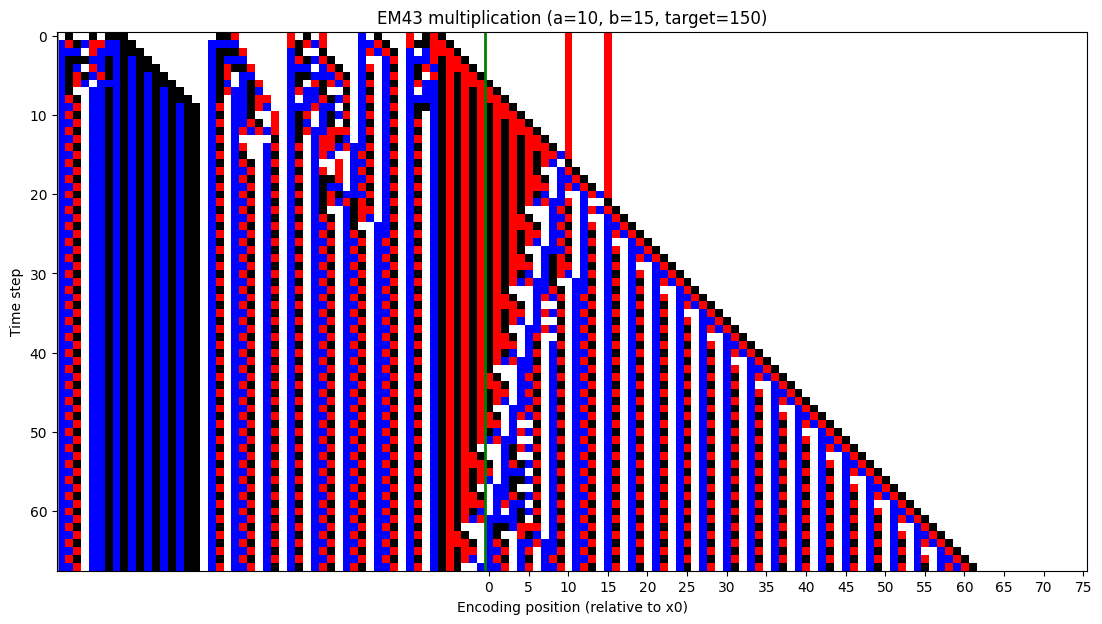

<Figure size 640x480 with 0 Axes>

In [5]:
# Space-time diagram for one held-out pair
# Change this pair if you want to inspect another case.
a_vis, b_vis = 10, 15
enc_vis_list, target_vis = build_two_input_task(
    pairs=[(a_vis, b_vis)], target_fn=target_fn
)
out = evaluator.run_single(
    rule_full=rule_full, program=program, enc=enc_vis_list[0],
    return_trajectory=True,
)
print("Input pair:", (a_vis, b_vis))
print("Prediction:", out["pred"])
print("Expected:", int(target_vis[0]))
print("Valid:", out["valid"])
print("Halt time:", out["halt_time"])
evaluator.plot_trajectory(
    out["trajectory"],
    title=f"EM43 multiplication (a={a_vis}, b={b_vis}, target={int(target_vis[0])})",
    figsize=(16, 7), tick_step=5,
)
plt.savefig(
    DRIVE_ROOT / f"multiply_ab_space_time_a{a_vis}_b{b_vis}.png",
    dpi=300, bbox_inches="tight",
)
plt.show()


# 4. Evaluation: quick probes or full held-out grid

In [6]:
# Evaluate each genome on held-out pairs.
# False = quick 7-pair probe (default).
# True = full held-out grid 0..30 with at least one input > 8 (880 pairs).
RUN_FULL_HELD_OUT_GRID = False

if RUN_FULL_HELD_OUT_GRID:
    test_pairs = [
        (a, b)
        for a in range(0, 31)
        for b in range(0, 31)
        if (a > 8 or b > 8)
    ]
    test_set_name = "held_out_grid_0_30_at_least_one_gt8"
else:
    test_pairs = list(probe_pairs)
    test_set_name = "representative_7_pair_probe"

encoded_inputs, targets = build_two_input_task(
    pairs=test_pairs, target_fn=target_fn
)
targets = np.asarray(targets, dtype=np.int64)

rows = []
for genome_path in genome_paths:
    data = np.load(genome_path, allow_pickle=True)
    current_rule = np.asarray(data["rule_full"], dtype=np.uint8).reshape(-1)
    current_program = np.asarray(data["program"], dtype=np.uint8).reshape(-1)
    enforce_immutables_full(current_rule)
    current_run = int(data["run"]) if "run" in data else int(genome_path.stem.split("_")[-1])
    current_eval = EM43NumpyEvaluator(
        Lp=len(current_program), Ls=4, T_max=10000,
        right_padding=20, extend_margin=3, extend_by=20,
    )
    preds = np.full(len(encoded_inputs), -1, dtype=np.int64)
    valid = np.zeros(len(encoded_inputs), dtype=bool)
    halt_times = np.full(len(encoded_inputs), -1, dtype=np.int64)
    for i, enc in enumerate(encoded_inputs):
        out = current_eval.run_single(
            rule_full=current_rule, program=current_program, enc=enc,
            return_trajectory=False,
        )
        preds[i] = -1 if out["pred"] is None else int(out["pred"])
        valid[i] = bool(out["valid"])
        halt_times[i] = -1 if out["halt_time"] is None else int(out["halt_time"])
    correct = valid & (preds == targets)
    valid_pred = valid & (preds >= 0)
    test_mae = (
        float(np.mean(np.abs(preds[valid_pred] - targets[valid_pred])))
        if np.any(valid_pred) else float("nan")
    )
    rows.append({
        "run": current_run,
        "test_set": test_set_name,
        "n_examples": int(len(targets)),
        "accuracy": float(correct.mean()),
        "valid_fraction": float(valid.mean()),
        "test_mae_valid_only": test_mae,
        "n_correct": int(correct.sum()),
        "n_wrong_or_invalid": int((~correct).sum()),
        "mean_halt_time_valid": float(halt_times[valid].mean()) if np.any(valid) else float("nan"),
        "genome_file": genome_path.name,
    })

rows.sort(key=lambda r: r["run"])
results_df = pd.DataFrame(rows)
display(results_df)
results_path = DRIVE_ROOT / "multiply_ab_extrapolation_results.csv"
results_df.to_csv(results_path, index=False)
print("Saved:", results_path)
print("IMPORTANT: test_set column identifies the probe or full grid used.")


,run,test_set,n_examples,accuracy,valid_fraction,test_mae_valid_only,n_correct,n_wrong_or_invalid,mean_halt_time_valid,genome_file
0,1,representative_7_pair_probe,7,0.0,1.0,299.285714,0,7,103.285714,best_em43_multiply_ab_run_001.npz
1,2,representative_7_pair_probe,7,0.0,1.0,310.000000,0,7,92.571429,best_em43_multiply_ab_run_002.npz


Saved: /content/drive/MyDrive/EM43/multiply_ab_extrapolation_results.csv
IMPORTANT: test_set column identifies the probe or full grid used.


# 5. Runtime analysis

In [7]:
# Runtime analysis on four two-input cases (Run 1)
import time
runtime_pairs = [(9, 9), (10, 15), (20, 25), (30, 30)]
runtime_enc, runtime_targets = build_two_input_task(
    pairs=runtime_pairs, target_fn=target_fn
)
runtime_rows = []
for (a, b), enc, expected in zip(runtime_pairs, runtime_enc, runtime_targets):
    evaluator.run_single(rule_full=rule_full, program=program, enc=enc, return_trajectory=False)
    timings = []
    last = None
    for _ in range(5):
        t0 = time.perf_counter()
        last = evaluator.run_single(
            rule_full=rule_full, program=program, enc=enc, return_trajectory=False
        )
        timings.append(time.perf_counter() - t0)
    runtime_rows.append({
        "task": task_alias, "run": 1, "a": a, "b": b,
        "expected": int(expected), "predicted": last["pred"],
        "valid": bool(last["valid"]),
        "correct": bool(last["valid"] and last["pred"] == int(expected)),
        "halt_time": last["halt_time"],
        "extensions": last["n_extensions"],
        "runtime_median_sec": float(np.median(timings)),
    })
runtime_df = pd.DataFrame(runtime_rows)
display(runtime_df)
runtime_path = DRIVE_ROOT / "multiply_ab_runtime_analysis.csv"
runtime_df.to_csv(runtime_path, index=False)
print("Saved:", runtime_path)


,task,run,a,b,expected,predicted,valid,correct,halt_time,extensions,runtime_median_sec
0,multiply_ab,1,9,9,81,62,True,False,69,2,0.008137
1,multiply_ab,1,10,15,150,60,True,False,67,2,0.002505
2,multiply_ab,1,20,25,500,110,True,False,117,4,0.004830
3,multiply_ab,1,30,30,900,160,True,False,167,6,0.007410


Saved: /content/drive/MyDrive/EM43/multiply_ab_runtime_analysis.csv
